# Which team stats best predict NBA wins?

**Step 3: train two models with a time-based split.**

Each row is one game from the home team's side. Features are home-minus-away differences (built in `src/build_features.py`). Target: did the home team win?

In [1]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, roc_auc_score, log_loss

df = pd.read_csv('../data/processed/game_features.csv')
FEATURES = ['EFG_PCT_DIFF', 'TOV_PCT_DIFF', 'OREB_PCT_DIFF', 'FT_RATE_DIFF',
            'REB_MARGIN', 'FG3A_RATE_DIFF', 'AST_RATE_DIFF',
            'STL_PER100_DIFF', 'BLK_PER100_DIFF', 'PACE', 'HOME']
df.groupby('SEASON').size().rename('games').to_frame().T

SEASON,2016-17,2017-18,2018-19,2019-20,2020-21,2021-22,2022-23,2023-24,2024-25,2025-26
games,1230,1230,1230,1059,1080,1230,1230,1230,1230,1230


## Time-based split (no random shuffling)

Train on the 7 earlier seasons and test on the 3 most recent ones. A random split would mix future games into training, so the model could pick up league-wide trends (like the rise of the 3-pointer) it wouldn't actually know in advance. Splitting by time copies how the model would be used for real.

In [2]:
TEST_SEASONS = ['2023-24', '2024-25', '2025-26']
train = df[~df.SEASON.isin(TEST_SEASONS)]
test = df[df.SEASON.isin(TEST_SEASONS)]
X_train, y_train = train[FEATURES], train['WIN']
X_test, y_test = test[FEATURES], test['WIN']
print(f'Train: {len(train):,} games ({train.SEASON.min()} to {train.SEASON.max()})')
print(f'Test:  {len(test):,} games ({test.SEASON.min()} to {test.SEASON.max()})')

Train: 8,289 games (2016-17 to 2022-23)
Test:  3,690 games (2023-24 to 2025-26)


## Models

- **Logistic regression**: simple and easy to explain. Features are standardized first so their coefficients can be compared directly.
- **Random forest**: many decision trees voting together. It can pick up non-linear effects and interactions.
- **Baseline**: always pick the home team. Any model has to beat this to be worth anything.

In [3]:
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
forest = RandomForestClassifier(n_estimators=400, min_samples_leaf=20,
                                random_state=42, n_jobs=-1)
logreg.fit(X_train, y_train)
forest.fit(X_train, y_train)

rows = []
base_p = np.full(len(y_test), y_train.mean())
rows.append(('Baseline: always pick home team', accuracy_score(y_test, np.ones(len(y_test))),
             0.5, log_loss(y_test, base_p)))
for name, model in [('Logistic regression', logreg), ('Random forest', forest)]:
    p = model.predict_proba(X_test)[:, 1]
    rows.append((name, accuracy_score(y_test, p > 0.5), roc_auc_score(y_test, p), log_loss(y_test, p)))
results = pd.DataFrame(rows, columns=['Model', 'Accuracy', 'ROC AUC', 'Log loss']).set_index('Model')
results.round(3)

,Accuracy,ROC AUC,Log loss
Model,,,
Baseline: always pick home team,0.547,0.500,0.690
Logistic regression,0.960,0.994,0.096
Random forest,0.930,0.985,0.217


**How to read this:** *Accuracy* is the share of test games called correctly. *ROC AUC* measures how well the model ranks winners above losers (0.5 = coin flip, 1.0 = perfect). *Log loss* checks whether the probabilities are well calibrated (lower is better).

In [4]:
# Accuracy for each test season: is performance stable over time?
by_season = test.assign(logreg=logreg.predict(X_test), forest=forest.predict(X_test))
by_season.groupby('SEASON').apply(
    lambda g: pd.Series({'Logistic regression': (g.logreg == g.WIN).mean(),
                         'Random forest': (g.forest == g.WIN).mean()}),
    include_groups=False).round(3)

,Logistic regression,Random forest
SEASON,,
2023-24,0.959,0.936
2024-25,0.965,0.937
2025-26,0.956,0.918


## What this means

- **Both models crush the baseline**: 96% vs 55%. Even without points, these stats nearly decide the game.
- **Why so high?** The features come from *the same game* being predicted, so this model **explains** why a team won. It does not forecast games before they happen. The question it answers is *which stats matter*, not *who will win tomorrow*.
- **Logistic regression beats the random forest.** The links between these stats and winning are mostly straight lines (shoot better → win more), so the extra flexibility of the forest doesn't help, and the simpler model is easier to explain.
- **Results hold across all 3 test seasons** (92–97%), so the model isn't relying on one unusual year.

# Step 4: which stats matter most?

Two ways to measure importance:
1. **Logistic regression coefficients**: features are standardized, so each coefficient means "how much the odds of winning change when this stat moves by one standard deviation". The sign shows the direction.
2. **Permutation importance** (works for both models): shuffle one feature in the *test* set and see how much accuracy drops. A big drop means the model relied on that feature. Using test data measures what matters for games the model hasn't seen.

In [5]:
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

BLUE, ORANGE = '#2a78d6', '#eb6834'
INK, INK2, GRID = '#0b0b0b', '#52514e', '#e4e3df'
LABELS = {'EFG_PCT_DIFF': 'Shooting efficiency (eFG%)', 'TOV_PCT_DIFF': 'Turnover rate',
          'OREB_PCT_DIFF': 'Offensive rebound %', 'FT_RATE_DIFF': 'Free throw rate',
          'REB_MARGIN': 'Rebound margin', 'FG3A_RATE_DIFF': '3-point attempt rate',
          'AST_RATE_DIFF': 'Assist rate', 'STL_PER100_DIFF': 'Steals per 100 poss.',
          'BLK_PER100_DIFF': 'Blocks per 100 poss.', 'PACE': 'Pace', 'HOME': 'Home court'}
plt.rcParams.update({'font.size': 11, 'axes.edgecolor': GRID, 'axes.labelcolor': INK2,
                     'xtick.color': INK2, 'ytick.color': INK, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.facecolor': '#fcfcfb',
                     'axes.facecolor': '#fcfcfb', 'savefig.dpi': 160})

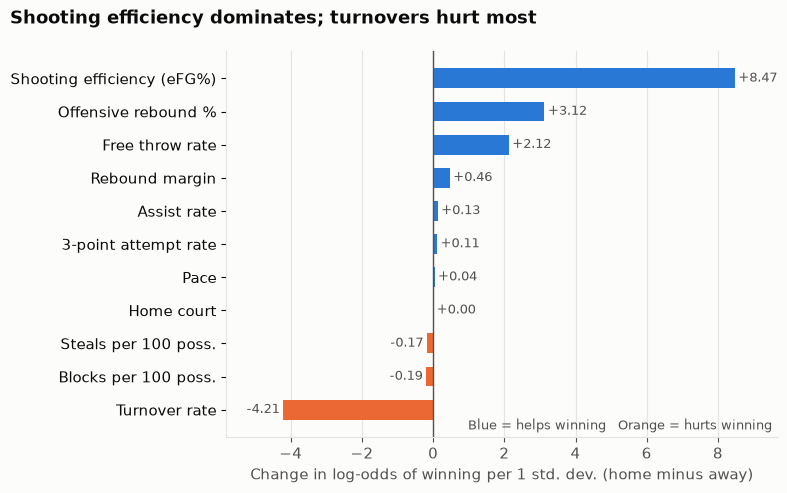

,coefficient
Shooting efficiency (eFG%),8.47
Turnover rate,-4.21
Offensive rebound %,3.12
Free throw rate,2.12
Rebound margin,0.46
Blocks per 100 poss.,-0.19
Steals per 100 poss.,-0.17
Assist rate,0.13
3-point attempt rate,0.11
Pace,0.04


In [6]:
coefs = pd.Series(logreg[-1].coef_[0], index=FEATURES).rename(LABELS).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
colors = [BLUE if v > 0 else ORANGE for v in coefs]
ax.barh(coefs.index, coefs.values, color=colors, height=0.6)
ax.axvline(0, color=INK2, lw=1)
ax.grid(axis='x', color=GRID, lw=0.8); ax.set_axisbelow(True)
for y, v in enumerate(coefs.values):
    ax.text(v + (0.1 if v >= 0 else -0.1), y, f'{v:+.2f}', va='center',
            ha='left' if v >= 0 else 'right', color=INK2, fontsize=9)
ax.set_xlim(coefs.min() - 1.6, coefs.max() + 1.2)
ax.set_xlabel('Change in log-odds of winning per 1 std. dev. (home minus away)')
fig.suptitle('Shooting efficiency dominates; turnovers hurt most', x=0.02, ha='left', color=INK, fontweight='bold')
ax.text(0.99, 0.02, 'Blue = helps winning   Orange = hurts winning', transform=ax.transAxes,
        ha='right', color=INK2, fontsize=9)
fig.tight_layout(); fig.savefig('../figures/logreg_coefficients.png'); plt.show()
coefs.sort_values(key=abs, ascending=False).round(2).to_frame('coefficient')

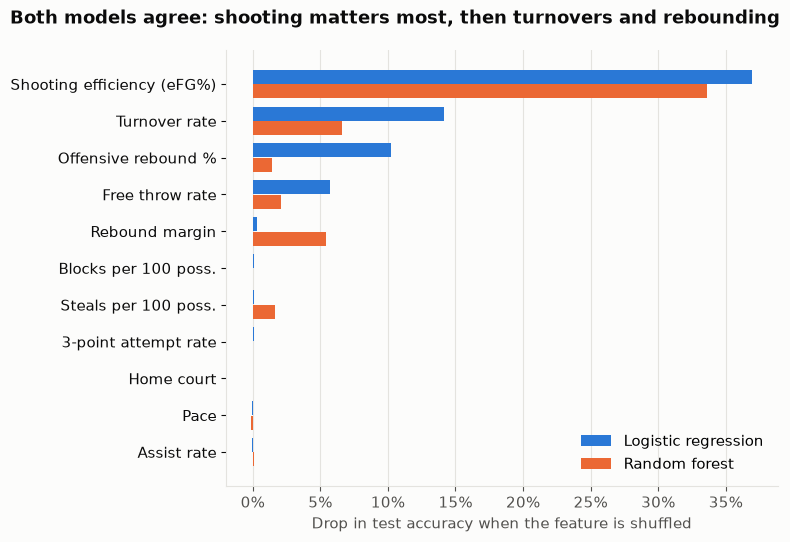

,Logistic regression,Random forest
Shooting efficiency (eFG%),37.0%,33.6%
Turnover rate,14.2%,6.6%
Offensive rebound %,10.2%,1.4%
Free throw rate,5.7%,2.1%
Rebound margin,0.3%,5.4%
Blocks per 100 poss.,0.1%,0.0%
Steals per 100 poss.,0.1%,1.7%
3-point attempt rate,0.1%,-0.0%
Home court,0.0%,0.0%
Pace,-0.0%,-0.1%


In [7]:
perm = {}
for name, model in [('Logistic regression', logreg), ('Random forest', forest)]:
    r = permutation_importance(model, X_test, y_test, scoring='accuracy',
                               n_repeats=10, random_state=42, n_jobs=-1)
    perm[name] = pd.Series(r.importances_mean, index=FEATURES)
perm = pd.DataFrame(perm).rename(index=LABELS).sort_values('Logistic regression')

fig, ax = plt.subplots(figsize=(8, 5.5))
y = np.arange(len(perm)); h = 0.38
ax.barh(y + h/2 + 0.01, perm['Logistic regression'], height=h, color=BLUE, label='Logistic regression')
ax.barh(y - h/2 - 0.01, perm['Random forest'], height=h, color=ORANGE, label='Random forest')
ax.set_yticks(y, perm.index)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.grid(axis='x', color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.set_xlabel('Drop in test accuracy when the feature is shuffled')
fig.suptitle('Both models agree: shooting matters most, then turnovers and rebounding', x=0.02, ha='left', color=INK, fontweight='bold')
ax.legend(frameon=False, loc='lower right')
fig.tight_layout(); fig.savefig('../figures/permutation_importance.png'); plt.show()
perm.sort_values('Logistic regression', ascending=False).map(lambda v: f'{v:.1%}')

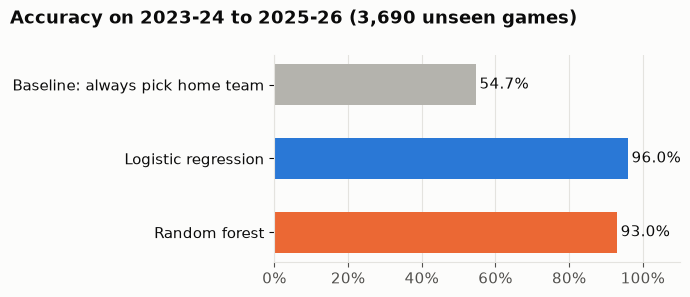

In [8]:
fig, ax = plt.subplots(figsize=(7, 3))
acc = results['Accuracy'].iloc[::-1]
ax.barh(acc.index, acc.values, color=[ORANGE, BLUE, '#b4b3ad'], height=0.55)
for yv, v in enumerate(acc.values):
    ax.text(v + 0.01, yv, f'{v:.1%}', va='center', color=INK)
ax.set_xlim(0, 1.1); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
ax.grid(axis='x', color=GRID, lw=0.8); ax.set_axisbelow(True)
fig.suptitle('Accuracy on 2023-24 to 2025-26 (3,690 unseen games)', x=0.02, ha='left', color=INK, fontweight='bold')
fig.tight_layout(); fig.savefig('../figures/model_accuracy.png'); plt.show()

## What this means

- **Shooting efficiency is king.** Shuffling eFG% costs both models about 35 points of accuracy, more than every other stat put together.
- **Then turnovers, offensive rebounding and free throws**: Dean Oliver's other "Four Factors", in roughly the order he suggested (shooting > turnovers > rebounding > free throws).
- **Pace, 3-point volume, assists and home court add almost nothing** once you know how efficiently each team played. Shooting *more* threes doesn't win games; making shots does. Home court only matters *through* the stats (home teams shoot a little better), not on top of them.
- **Rebound margin vs. offensive rebound %:** the two overlap. Logistic regression gives the credit to OREB%, while the random forest leans on rebound margin. Correlated features share importance, so read them together.